# Hotel Cancellation Prediction
**Suffolk University · ISOM 835 · Fall 2026**  
**Team: Ctrl_+_Alt_+_Defeat**  
Anshuman Agrawal · Mark Belov · Phuc Hoang · Sarah Legault

Predict the probability that each hotel booking will be canceled. This notebook contains the complete workflow; no `src` folder or earlier notebook is required. Run cells from top to bottom.

AI assistance: ChatGPT and OpenAI coding tools supported coding, debugging, analysis and drafting. Team review is pending.

**Contents:** 1 Setup · 2 Data checks · 3 Exploration · 4 Leakage review · 5 Features and pipelines · 6 Experiments · 7 Model comparison · 8 Calibration and robustness · 9 Submission · 10 Project summary.

The four-member team exception was confirmed by the user. Final prediction-time review, model approval and Kaggle/Canvas upload confirmations remain pending. No leaderboard scores are inferred.

## 1. Setup
Local: open this notebook from the repository and use the pinned requirements. Colab: the notebook is self-contained; upload only the three authorized CSVs when prompted. Keep competition data private. Seed 835 preserves the original baseline splits. Full validation runs ten models over the same five stratified folds.

In [1]:
from pathlib import Path
import os, sys, subprocess, json, hashlib, time, uuid, warnings
from datetime import datetime, timezone
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'numpy==2.2.6', 'pandas==2.2.3', 'scikit-learn==1.6.1',
                    'matplotlib==3.10.3', 'seaborn==0.13.2'], check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# The notebook works from either the repository root or notebooks/.
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA_DIR = Path(os.environ.get('DATA_DIR', ROOT / 'data'))
TEAM_NAME = 'Ctrl_+_Alt_+_Defeat'
SEED = 835
TARGET = 'is_canceled'
TRAIN_ROWS, TEST_ROWS = 83573, 35817
KNOWN_LEAKS = ('reservation_status', 'reservation_status_date', 'assigned_room_type')
UNCERTAIN = ('booking_changes', 'days_in_waiting_list', 'total_of_special_requests',
             'agent', 'company', 'country', 'deposit_type')
RUN_EXPERIMENTS = True  # False shows saved comparisons without retraining (local repository only).
CREATE_DRAFT_SUBMISSION = True
for folder in [DATA_DIR, ROOT/'results/figures', ROOT/'experiments', ROOT/'classwork']:
    folder.mkdir(parents=True, exist_ok=True)
print('Project folder:', ROOT)
print('Team:', TEAM_NAME, '| Seed:', SEED)

Project folder: /workspace/Hotel_Cancellation_Prediction_Model
Team: Ctrl_+_Alt_+_Defeat | Seed: 835


## 2. Load and validate competition data
Required inputs: `train.csv` (83,573 rows), `test.csv` (35,817 rows), `sample_submission.csv`. Checks cover dimensions, target, feature schemas, unique/disjoint IDs, sample alignment and known outcome fields. No external dataset is downloaded.

In [2]:
import hashlib
import pandas as pd

def validate_data(train, test, sample, expected_rows=(TRAIN_ROWS, TEST_ROWS)):
    if (len(train), len(test)) != expected_rows:
        raise ValueError(f'Expected train/test rows {expected_rows}, got {(len(train), len(test))}')
    for frame, name in [(train,'train'), (test,'test'), (sample,'sample')]:
        if 'id' not in frame or frame.id.isna().any() or frame.id.duplicated().any():
            raise ValueError(f'{name}: missing or duplicate IDs')
        if frame.columns.duplicated().any(): raise ValueError('Duplicate columns')
    if TARGET not in train or TARGET in test: raise ValueError('Target schema invalid')
    if train[TARGET].isna().any() or set(train[TARGET].unique()) != {0,1}: raise ValueError('Target must contain both binary classes')
    if set(train.columns) - {TARGET} != set(test.columns): raise ValueError('Feature schema mismatch')
    if list(sample.columns) != ['id', TARGET] or len(sample) != len(test): raise ValueError('Sample schema/length invalid')
    if set(sample.id) != set(test.id): raise ValueError('Sample/test IDs differ')
    if set(train.id) & set(test.id): raise ValueError('Train/test IDs overlap')
    bad = set(KNOWN_LEAKS) & (set(train) | set(test))
    if bad: raise ValueError(f'Known outcome leakage present: {sorted(bad)}')
    return {'train_rows': len(train), 'test_rows': len(test), 'cancellation_rate': float(train[TARGET].mean())}



names = ['train.csv', 'test.csv', 'sample_submission.csv']
missing = [name for name in names if not (DATA_DIR/name).is_file()]
if missing and IN_COLAB:
    from google.colab import files
    print('Upload the three authorized competition CSVs. Files remain in this runtime.')
    uploaded = files.upload()
    for name, content in uploaded.items():
        if name in names:
            (DATA_DIR/name).write_bytes(content)
missing = [name for name in names if not (DATA_DIR/name).is_file()]
if missing:
    raise FileNotFoundError('Place authorized files in data/: ' + ', '.join(missing))
train, test, sample = [pd.read_csv(DATA_DIR/name) for name in names]
data_summary = validate_data(train, test, sample)
data_hashes = {name: hashlib.sha256((DATA_DIR/name).read_bytes()).hexdigest() for name in names}
data_summary['sha256'] = data_hashes
(ROOT/'results/data_summary.json').write_text(json.dumps(data_summary, indent=2))
display(pd.DataFrame([{'training_rows':len(train), 'test_rows':len(test),
                       'features':len(test.columns)-1, 'cancellation_rate':train[TARGET].mean()}]))
print('Data validation: PASS')

,training_rows,test_rows,features,cancellation_rate
0,83573,35817,28,0.370419


Data validation: PASS


## 3. Explore cancellations
Compare missingness, lead time, hotel, deposit type, country, special requests and arrival seasonality. These are associations, not causal effects. Keep denominators visible, especially for small groups. `No Deposit` must not automatically be treated as `Refundable`. All existing full-resolution figures remain in `results/figures/`.

,missing_share
company,0.943726
agent,0.137365
country,0.003889
children,0.000036


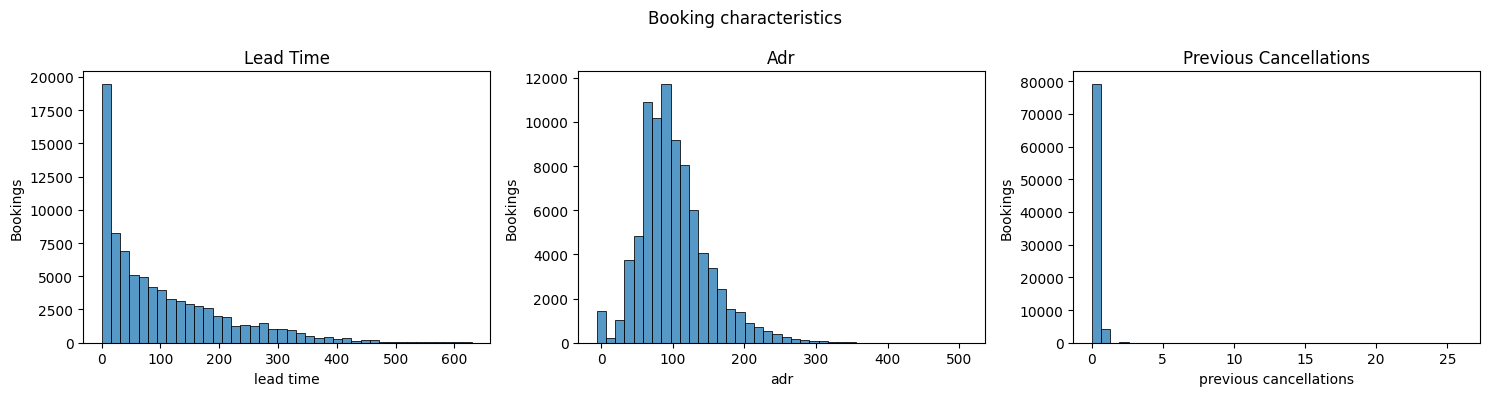

,bookings,cancellation_rate
deposit_type,,
No Deposit,73348,0.284807
Non Refund,10107,0.993668
Refundable,118,0.203390


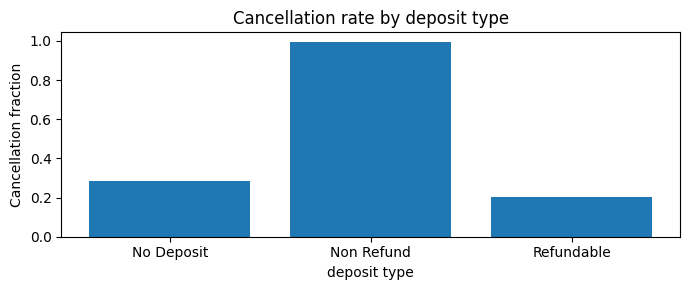

,bookings,cancellation_rate
total_of_special_requests,,
0,49207,0.476111
1,23265,0.220417
2,9085,0.225427
3,1741,0.186100
4,244,0.110656
5,31,0.064516


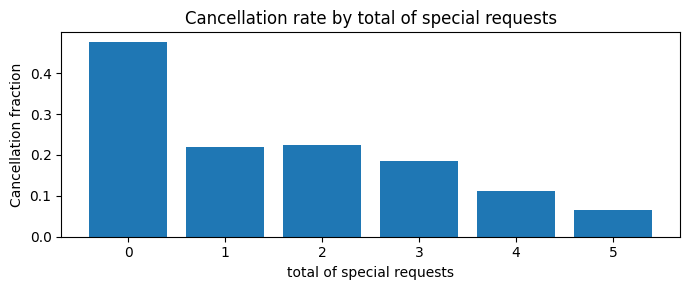

,bookings,cancellation_rate
Elsewhere,49446,0.238260
Missing country,325,0.129231
Portugal,33802,0.566061


Interpretation: observed policy, country and request patterns may reflect market mix or changing reservation states.


In [3]:
missingness = train.isna().mean().sort_values(ascending=False).rename('missing_share')
display(missingness[missingness > 0].to_frame())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ['lead_time', 'adr', 'previous_cancellations']):
    sns.histplot(train[column].dropna(), bins=40, ax=ax)
    ax.set(title=column.replace('_', ' ').title(), xlabel=column.replace('_', ' '), ylabel='Bookings')
fig.suptitle('Booking characteristics'); fig.tight_layout()
fig.savefig(ROOT/'results/figures/booking_characteristics.png', dpi=150); plt.show()

puzzle_tables = {}
for column in ['deposit_type', 'total_of_special_requests', 'hotel', 'market_segment',
               'distribution_channel', 'agent', 'company', 'country', 'booking_changes', 'arrival_date_month']:
    table = train.groupby(column, dropna=False)[TARGET].agg(bookings='size', cancellation_rate='mean')
    if column in ['deposit_type', 'total_of_special_requests']:
        puzzle_tables[column] = table
        display(table)
        fig, ax = plt.subplots(figsize=(7, 3))
        ax.bar(table.index.astype(str), table.cancellation_rate)
        ax.set(title='Cancellation rate by '+column.replace('_',' '),
               xlabel=column.replace('_',' '), ylabel='Cancellation fraction')
        fig.tight_layout(); fig.savefig(ROOT/f'results/figures/rate_{column}.png', dpi=150); plt.show()
country_group = pd.Series('Elsewhere', index=train.index)
country_group[train.country == 'PRT'] = 'Portugal'
country_group[train.country.isna()] = 'Missing country'
country_table = train.groupby(country_group)[TARGET].agg(bookings='size', cancellation_rate='mean')
display(country_table)
print('Interpretation: observed policy, country and request patterns may reflect market mix or changing reservation states.')

## 4. Leakage review
The provisional operational prediction moment is **booking creation**. The three outcome fields are verified absent. The conservative model excludes the seven uncertain fields listed below, but remaining fields such as ADR, parking and prior history still need timestamp evidence. A high AUC does not prove safety. Compare uncertain-field inclusion with the same model/splits; treat AUC above 0.985 as a warning requiring review. Row-local engineered features inherit their inputs’ timing.

In [4]:
assert not set(KNOWN_LEAKS) & (set(train) | set(test))
leakage_rows = []
for column in test.columns:
    decision = 'Drop identifier' if column == 'id' else 'Exclude from conservative model' if column in UNCERTAIN else 'Retain provisionally; review timing'
    leakage_rows.append({'feature':column, 'decision':decision,
                         'availability':'Unverified at booking creation' if column!='id' else 'Identifier, not a predictor'})
leakage_table = pd.DataFrame(leakage_rows)
display(leakage_table)
# Detailed prior decisions remain in experiments/leakage_decisions.csv when running locally.
leakage_table.to_csv(ROOT/'results/leakage_review.csv', index=False)

,feature,decision,availability
0,id,Drop identifier,"Identifier, not a predictor"
1,hotel,Retain provisionally; review timing,Unverified at booking creation
2,lead_time,Retain provisionally; review timing,Unverified at booking creation
3,arrival_date_year,Retain provisionally; review timing,Unverified at booking creation
4,arrival_date_month,Retain provisionally; review timing,Unverified at booking creation
5,arrival_date_week_number,Retain provisionally; review timing,Unverified at booking creation
6,arrival_date_day_of_month,Retain provisionally; review timing,Unverified at booking creation
7,stays_in_weekend_nights,Retain provisionally; review timing,Unverified at booking creation
8,stays_in_week_nights,Retain provisionally; review timing,Unverified at booking creation
9,adults,Retain provisionally; review timing,Unverified at booking creation


## 5. Feature engineering and model pipelines
Imputation, scaling and encoding are fitted **inside each training fold**. Agent/company are labels in the corrected models; they remain numeric only in the baseline. Features include total nights/guests, weekend share, prior-cancellation and repeat-guest indicators, and log lead time. Tree complexity is limited. Boosting uses ordinal encoding and early stopping on an internal training subset, never on the outer validation fold.

In [5]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class BookingFeatures(TransformerMixin, BaseEstimator):
    """Row-local transforms only; no population statistics or target inputs."""
    def __init__(self, conservative=True, engineered=False, categorical_ids=True, drop_features=()):
        self.conservative=conservative
        self.engineered=engineered
        self.categorical_ids=categorical_ids
        self.drop_features=drop_features
    def fit(self, X, y=None): return self
    def transform(self, X):
        X=X.copy().drop(columns=['id','is_canceled',*KNOWN_LEAKS,*self.drop_features],errors='ignore')
        if self.conservative: X=X.drop(columns=list(UNCERTAIN),errors='ignore')
        if self.categorical_ids:
            for c in ('agent','company'):
                if c in X: X[c]=X[c].map(lambda v: str(v) if not pd.isna(v) else 'missing')
        if self.engineered:
            if {'stays_in_weekend_nights','stays_in_week_nights'} <= set(X):
                X['total_nights']=X.stays_in_weekend_nights+X.stays_in_week_nights
                X['weekend_share']=X.stays_in_weekend_nights / X.total_nights.replace(0,np.nan)
            if {'adults','children','babies'} <= set(X): X['total_guests']=X.adults+X.children+X.babies
            if 'previous_cancellations' in X: X['previous_cancel_indicator']=(X.previous_cancellations>0).astype(int)
            if 'is_repeated_guest' in X: X['returning_guest_indicator']=X.is_repeated_guest
            if 'lead_time' in X: X['log_lead_time']=np.log1p(X.lead_time.clip(lower=0))
        return X

from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def build_pipeline(model='logistic', conservative=True, engineered=False, categorical_ids=True, drop_features=(), **params):
    numeric=Pipeline([('imp',SimpleImputer(strategy='median',keep_empty_features=True)),('sc',StandardScaler())])
    encoding = OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1) if model=='hist' else OneHotEncoder(handle_unknown='ignore',min_frequency=20)
    categorical=Pipeline([('imp',SimpleImputer(strategy='constant',fill_value='missing',keep_empty_features=True)),('encode',encoding)])
    prep=ColumnTransformer([('num',numeric,make_column_selector(dtype_include='number')),('cat',categorical,make_column_selector(dtype_exclude='number'))])
    estimators={
      'logistic':lambda:LogisticRegression(max_iter=3000,random_state=SEED),
      'tree':lambda:DecisionTreeClassifier(max_depth=8,min_samples_leaf=20,random_state=SEED),
      'forest':lambda:RandomForestClassifier(n_estimators=200,max_depth=16,min_samples_leaf=5,n_jobs=2,random_state=SEED),
      'hist':lambda:HistGradientBoostingClassifier(max_iter=250,max_leaf_nodes=15,l2_regularization=2,early_stopping=True,random_state=SEED)}
    if model not in estimators: raise ValueError(f'Unknown model: {model}')
    clf=estimators[model]().set_params(**params)
    return Pipeline([('features',BookingFeatures(conservative,engineered,categorical_ids,drop_features)),('prep',prep),('clf',clf)])

## 6. Run reproducible experiments
Ten configurations use identical five-fold stratified splits, seed 835. We record fold AUC, mean/SD, OOF Brier/log loss, duration, data hashes, exact settings and feature lists. HistGradientBoosting’s ordinal encoding is a practical candidate rather than native categorical handling. Optional external boosting/ensembles are not part of this notebook. New runs append to the experiment history; errors are recorded and raised.

In [6]:
import numpy as np
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

def evaluate(model, X, y, splitter=None, groups=None):
    splitter=splitter or StratifiedKFold(5,shuffle=True,random_state=SEED)
    oof=np.full(len(y),np.nan); scores=[]; fitted=[]
    for fold,(a,b) in enumerate(splitter.split(X,y,groups),1):
        if len(set(y.iloc[b]))!=2: raise ValueError('A fold has only one target class')
        m=clone(model).fit(X.iloc[a],y.iloc[a]);p=m.predict_proba(X.iloc[b])[:,1]
        oof[b]=p;scores.append(float(roc_auc_score(y.iloc[b],p)));fitted.append(m)
    mask=np.isfinite(oof)
    return {'fold_auc':scores,'mean_auc':float(np.mean(scores)),'std_auc':float(np.std(scores)),
            'brier':float(brier_score_loss(y[mask],oof[mask])),'log_loss':float(log_loss(y[mask],oof[mask])),
            'oof':oof,'fitted':fitted}

EXPERIMENTS = [
    ('Logistic baseline', dict(model='logistic', conservative=False, categorical_ids=False)),
    ('Logistic with categorical IDs', dict(model='logistic', conservative=False)),
    ('Logistic with engineered features', dict(model='logistic', conservative=False, engineered=True)),
    ('Conservative logistic', dict(model='logistic', conservative=True)),
    ('Conservative engineered logistic', dict(model='logistic', conservative=True, engineered=True)),
    ('Decision tree', dict(model='tree', conservative=True, engineered=True)),
    ('Random forest', dict(model='forest', conservative=True, engineered=True)),
    ('Conservative gradient boosting', dict(model='hist', conservative=True, engineered=True)),
    ('Exploratory gradient boosting', dict(model='hist', conservative=False, engineered=True)),
    ('Regularized conservative boosting', dict(model='hist', conservative=True, engineered=True,
        max_leaf_nodes=31, l2_regularization=5, learning_rate=0.07, max_iter=350)),
]
X, y = train.drop(columns=TARGET), train[TARGET]
run_results, oof_predictions = {}, {}
new_history, new_folds = [], []
for experiment_name, settings in EXPERIMENTS if RUN_EXPERIMENTS else []:
    started = time.monotonic()
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')+'_'+uuid.uuid4().hex[:8]
    try:
        pipeline = build_pipeline(**settings)
        measured = evaluate(pipeline, X, y)
        features_used = list(pipeline['features'].transform(X).columns)
        record = dict(experiment_name=experiment_name, experiment_id=run_id,
                      run_date=datetime.now(timezone.utc).isoformat(), status='MEASURED',
                      model_name=settings['model'], conservative=settings.get('conservative',True),
                      mean_cv_auc=measured['mean_auc'], std_cv_auc=measured['std_auc'],
                      brier=measured['brier'], log_loss=measured['log_loss'],
                      training_duration_seconds=time.monotonic()-started, random_seed=SEED,
                      settings=json.dumps(settings), features_used=json.dumps(features_used),
                      data_hashes=json.dumps(data_hashes), notes='Timing review pending')
        for fold, score in enumerate(measured['fold_auc'], 1):
            record[f'fold_{fold}_auc'] = score
            new_folds.append(dict(experiment_name=experiment_name, experiment_id=run_id, fold=fold, auc=score))
        if record['mean_cv_auc'] > 0.985:
            record['notes'] = 'HIGH AUC: documented leakage review required'
        new_history.append(record)
        run_results[experiment_name] = record
        oof_predictions[experiment_name] = measured['oof']
        print(f"{experiment_name}: AUC {measured['mean_auc']:.5f} ± {measured['std_auc']:.5f}")
    except Exception as error:
        new_history.append(dict(experiment_name=experiment_name, experiment_id=run_id,
                                status='FAILED', notes=f'{type(error).__name__}: {error}'))
        raise
    finally:
        # Preserve all measured/failed runs even if a later configuration fails.
        for filename, rows in [('experiment_log.csv',new_history),('fold_scores.csv',new_folds)]:
            if rows:
                path = ROOT/'experiments'/filename
                prior = pd.read_csv(path) if path.exists() else pd.DataFrame()
                combined = pd.concat([prior,pd.DataFrame(rows)], ignore_index=True)
                combined.to_csv(path, index=False)
        new_history.clear(); new_folds.clear()
if RUN_EXPERIMENTS:
    path = ROOT/'experiments/experiment_details.json'
    previous = json.loads(path.read_text()) if path.exists() else {}
    # Historical run IDs/settings remain in the append-only CSV above.
    previous.update(run_results)
    path.write_text(json.dumps(previous, indent=2))
else:
    path = ROOT/'experiments/experiment_details.json'
    if not path.exists(): raise FileNotFoundError('No saved runs: enable RUN_EXPERIMENTS')
    run_results = json.loads(path.read_text())

/workspace/isom835-venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/workspace/isom835-venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/workspace/isom835-venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/workspace/isom835-venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/workspace/isom835-venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


...

Decision tree: AUC 0.81937 ± 0.00365


Random forest: AUC 0.88252 ± 0.00377


Conservative gradient boosting: AUC 0.87340 ± 0.00439


Exploratory gradient boosting: AUC 0.94471 ± 0.00106


Regularized conservative boosting: AUC 0.88323 ± 0.00342


## 7. Compare models and feature ablations
Primary selection uses defensible validation rather than the public leaderboard. Compare categorical IDs and engineered features using the same model/folds. Adding uncertain fields is a bundled sensitivity analysis, not evidence that they are safe. Repeated model selection on these folds can make the reported best score optimistic.

,experiment,mean_auc,fold_sd,brier,log_loss,conservative
8,Exploratory gradient boosting,0.94471,0.00106,0.09131,0.28449,False
2,Logistic with engineered features,0.91597,0.00165,0.11142,0.34481,False
1,Logistic with categorical IDs,0.90740,0.00168,0.11727,0.36290,False
0,Logistic baseline,0.88936,0.00187,0.12608,0.38828,False
9,Regularized conservative boosting,0.88323,0.00342,0.12942,0.39532,True
6,Random forest,0.88252,0.00377,0.13252,0.40729,True
7,Conservative gradient boosting,0.87340,0.00439,0.13493,0.41036,True
5,Decision tree,0.81937,0.00365,0.15581,0.46948,True
4,Conservative engineered logistic,0.81530,0.00343,0.16179,0.48717,True
3,Conservative logistic,0.80280,0.00401,0.16599,0.50321,True


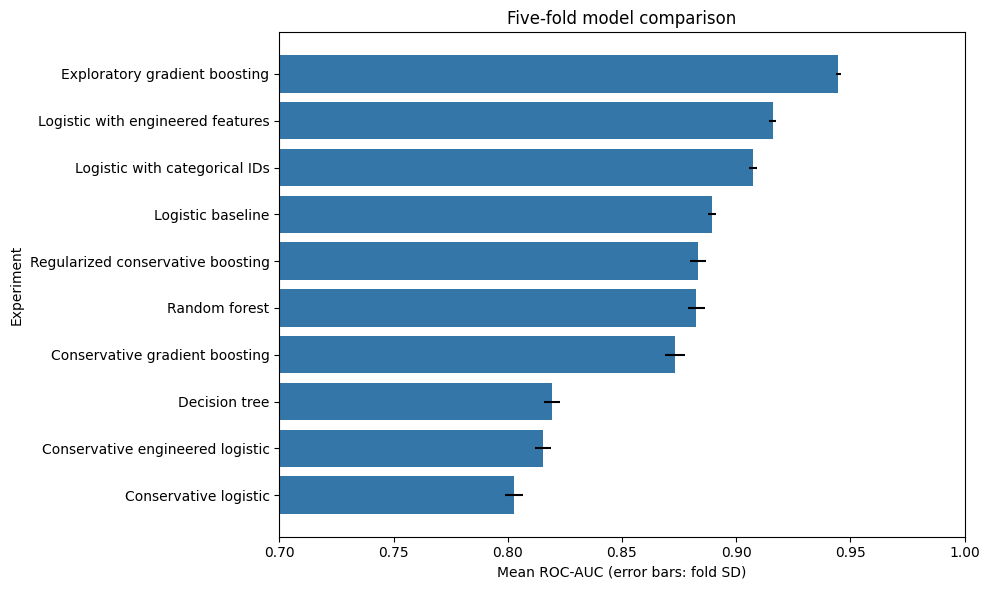

,experiment,comparison,change,auc_difference
0,Logistic with categorical IDs,Logistic baseline,Categorical ID encoding,0.01804
1,Logistic with engineered features,Logistic with categorical IDs,Engineered features,0.00857
2,Conservative engineered logistic,Conservative logistic,Conservative engineered features,0.01250
3,Exploratory gradient boosting,Conservative gradient boosting,Seven uncertain fields included,0.07131
4,Regularized conservative boosting,Conservative gradient boosting,Boosting parameter changes,0.00983


No model is approved solely because its AUC is highest.


In [7]:
comparison_rows = []
for name, record in run_results.items():
    comparison_rows.append({'experiment':name,
        'mean_auc':record.get('mean_cv_auc', record.get('mean_auc')),
        'fold_sd':record.get('std_cv_auc', record.get('std_auc')),
        'brier':record['brier'], 'log_loss':record['log_loss'],
        'conservative':record.get('conservative', 'Conservative' in name or name in ['Decision tree','Random forest'])})
comparison = pd.DataFrame(comparison_rows).sort_values('mean_auc', ascending=False)
comparison.to_csv(ROOT/'results/model_comparison.csv', index=False)
display(comparison.round(5))
fig, ax = plt.subplots(figsize=(10, 6))
ordered = comparison.sort_values('mean_auc')
ax.barh(ordered.experiment, ordered.mean_auc, xerr=ordered.fold_sd, color='#3576a8')
ax.set(title='Five-fold model comparison', xlabel='Mean ROC-AUC (error bars: fold SD)', ylabel='Experiment')
ax.set_xlim(0.7, 1.0); fig.tight_layout()
fig.savefig(ROOT/'results/figures/model_comparison.png', dpi=160); plt.show()
pairs = [('Logistic with categorical IDs','Logistic baseline','Categorical ID encoding'),
         ('Logistic with engineered features','Logistic with categorical IDs','Engineered features'),
         ('Conservative engineered logistic','Conservative logistic','Conservative engineered features'),
         ('Exploratory gradient boosting','Conservative gradient boosting','Seven uncertain fields included'),
         ('Regularized conservative boosting','Conservative gradient boosting','Boosting parameter changes')]
ablations = []
for changed, reference, description in pairs:
    a = float(comparison.set_index('experiment').loc[changed,'mean_auc'])
    b = float(comparison.set_index('experiment').loc[reference,'mean_auc'])
    ablations.append({'experiment':changed, 'comparison':reference, 'change':description, 'auc_difference':a-b})
display(pd.DataFrame(ablations).round(5))
pd.DataFrame(ablations).to_csv(ROOT/'results/feature_ablation.csv', index=False)
print('No model is approved solely because its AUC is highest.')

## 8. Calibration and secondary robustness
OOF Brier/log loss assess probability quality; ROC-AUC assesses ranking. A calibrated, stable model may support expected cancellation counts, but policy changes also require capacity/cost evidence. Secondary validation holds out agents and orders estimated booking dates. These are different deployment scenarios. A large missing-agent group can distort group splits, arrival/lead-time fields may have been revised, and early temporal rows are intentionally unscored.

Conservative candidate: Regularized conservative boosting (timing review pending)


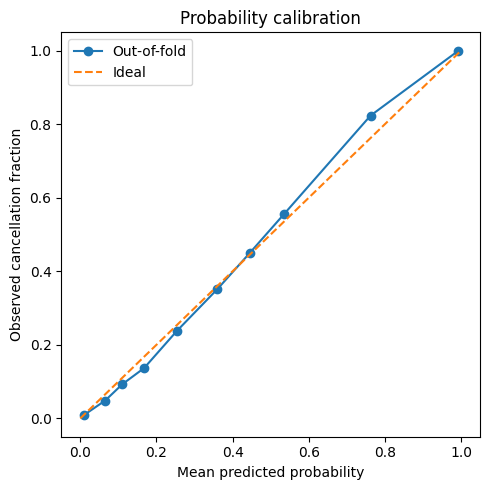

,validation,mean_auc,fold_sd
0,Held-out agent,0.805406,0.074016
1,Estimated booking time,0.778245,0.019318


In [8]:
from sklearn.calibration import calibration_curve
from sklearn.model_selection import GroupKFold, TimeSeriesSplit
candidate_name = comparison[comparison.conservative].iloc[0].experiment
candidate_settings = dict(next(settings for name, settings in EXPERIMENTS if name == candidate_name))
print('Conservative candidate:', candidate_name, '(timing review pending)')
if RUN_EXPERIMENTS:
    predicted = oof_predictions[candidate_name]
    observed, predicted_bins = calibration_curve(y, predicted, n_bins=10, strategy='quantile')
    fig, ax = plt.subplots(figsize=(5,5))
    ax.plot(predicted_bins, observed, 'o-', label='Out-of-fold'); ax.plot([0,1],[0,1],'--',label='Ideal')
    ax.set(title='Probability calibration', xlabel='Mean predicted probability', ylabel='Observed cancellation fraction')
    ax.legend(); fig.tight_layout(); fig.savefig(ROOT/'results/figures/calibration.png', dpi=150); plt.show()
    candidate = build_pipeline(**candidate_settings)
    group_results = evaluate(candidate, X, y, GroupKFold(5), train.agent.fillna(-1).astype(str))
    arrival = pd.to_datetime(train.arrival_date_year.astype(str)+'-'+train.arrival_date_month+'-'+
                             train.arrival_date_day_of_month.astype(str), format='%Y-%B-%d')
    booking_date = arrival - pd.to_timedelta(train.lead_time,unit='D')
    order = np.argsort(booking_date.to_numpy(), kind='stable')
    dates = booking_date.iloc[order].reset_index(drop=True)
    unique_dates = np.sort(dates.unique())
    time_splits = []
    for a,b in TimeSeriesSplit(5).split(unique_dates):
        time_splits.append((np.flatnonzero(dates.isin(unique_dates[a])), np.flatnonzero(dates.isin(unique_dates[b]))))
    class BookingTimeSplits:
        def split(self, *args): return iter(time_splits)
    time_results = evaluate(candidate, X.iloc[order].reset_index(drop=True), y.iloc[order].reset_index(drop=True), BookingTimeSplits())
    robustness = {'candidate':candidate_name,
        'group_agent':{k:v for k,v in group_results.items() if k not in ['oof','fitted']},
        'estimated_booking_time':{k:v for k,v in time_results.items() if k not in ['oof','fitted']},
        'time_coverage':float(np.isfinite(time_results['oof']).mean()),
        'caveats':'Agent missing-group imbalance; estimated dates may reflect revisions; earliest temporal rows unscored. Diagnostic, not primary CV.'}
    (ROOT/'results/robustness.json').write_text(json.dumps(robustness, indent=2))
else:
    robustness = json.loads((ROOT/'results/robustness.json').read_text())
display(pd.DataFrame([{'validation':'Held-out agent', 'mean_auc':robustness['group_agent']['mean_auc'],
                      'fold_sd':robustness['group_agent']['std_auc']},
                     {'validation':'Estimated booking time', 'mean_auc':robustness['estimated_booking_time']['mean_auc'],
                      'fold_sd':robustness['estimated_booking_time']['std_auc']}]))

## 9. Train, predict and validate the submission
Fit the strongest conservative candidate on all labeled training rows and produce genuine probabilities in official sample order. The filename stays **DRAFT** until feature-timing and final model review are completed. This technical check does not imply a Kaggle/Canvas upload. CSVs remain private and are ignored by Git. No class labels, fake rows or leaderboard scores are generated.

In [9]:
import hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd

def validate_submission(sub,test,sample,expected_rows=TEST_ROWS):
    if list(sub.columns)!=['id',TARGET]: raise ValueError('Columns must be exactly id,is_canceled')
    if len(sub)!=expected_rows or len(test)!=expected_rows or len(sample)!=expected_rows: raise ValueError('Incorrect row count')
    for f in (sub,test,sample):
        if f.id.isna().any() or f.id.duplicated().any(): raise ValueError('Missing/duplicate IDs')
    if list(sample.columns)!=['id',TARGET]: raise ValueError('Sample columns invalid')
    if not sub.id.reset_index(drop=True).equals(sample.id.reset_index(drop=True)): raise ValueError('Must follow sample ID order exactly')
    if set(sub.id)!=set(test.id): raise ValueError('Test IDs differ')
    if not pd.api.types.is_numeric_dtype(sub[TARGET]): raise ValueError('Predictions must be numeric')
    p=sub[TARGET].to_numpy(dtype=float)
    if not np.isfinite(p).all() or ((p<0)|(p>1)).any(): raise ValueError('Nonfinite or out-of-range probabilities')
    if np.isin(p,[0,1]).all(): raise ValueError('Thresholded labels detected; continuous probabilities required')
    return True



if CREATE_DRAFT_SUBMISSION:
    final_candidate = build_pipeline(**candidate_settings).fit(X, y)
    probabilities = pd.Series(final_candidate.predict_proba(test)[:,1], index=test.id)
    submission = sample[['id']].copy()
    submission[TARGET] = submission.id.map(probabilities)
    validate_submission(submission, test, sample)
    output = ROOT/'classwork'/f'{TEAM_NAME}_submission_DRAFT.csv'
    # Preserve a changed earlier draft locally before replacing its readable current filename.
    if output.exists() and not pd.read_csv(output).equals(submission):
        archive = ROOT/'local_submission_history'
        archive.mkdir(exist_ok=True)
        old_hash = hashlib.sha256(output.read_bytes()).hexdigest()[:12]
        (archive/f'{old_hash}_draft.csv').write_bytes(output.read_bytes())
    submission.to_csv(output,index=False)
    validate_submission(pd.read_csv(output),test,sample)
    validation = {'status':'Technically validated DRAFT; timing/model review pending',
        'candidate':candidate_name, 'rows':len(submission), 'columns':list(submission),
        'sha256':hashlib.sha256(output.read_bytes()).hexdigest(),
        'checked_at_utc':datetime.now(timezone.utc).isoformat(),
        'checks':['Exact sample ID order','Complete unique test IDs','35,817 rows',
                  'Finite continuous probabilities in [0,1]','CSV read-back validation'],
        'kaggle_upload':'Not confirmed','canvas_upload':'Not confirmed'}
    (ROOT/'results/submission_validation.json').write_text(json.dumps(validation,indent=2))
    print('Saved:',output.name, '| all technical checks PASS | final review PENDING')

Saved: Ctrl_+_Alt_+_Defeat_submission_DRAFT.csv | all technical checks PASS | final review PENDING


## 10. Project summary
Measured results, figures and experiment history are saved with readable filenames. `classwork/` contains only draft submission materials. Before treating them as final: resolve feature availability, review the memo and presentation, confirm competition rules, and record actual upload receipts. At least one random-forest submission is required; no upload is performed by this notebook. Public/private Kaggle scores remain pending.

In [10]:
summary = [
    '# Hotel cancellation results',
    f'Team: {TEAM_NAME}',
    f'Data: {len(train):,} labeled bookings and {len(test):,} test bookings.',
    'Five-fold stratified validation; seed 835; all learned preprocessing inside folds.',
    '', '## Measured experiments',
    '| Experiment | Mean ROC-AUC | Fold SD |', '|---|---:|---:|',
]
for row in comparison.itertuples():
    summary.append(f'| {row.experiment} | {row.mean_auc:.5f} | {row.fold_sd:.5f} |')
summary += ['', '## Interpretation',
    f'Highest conservative candidate: {candidate_name}. Timing approval remains pending.',
    'Exploratory performance includes uncertain fields and is not certified leak-free.',
    f"Held-out-agent AUC: {robustness['group_agent']['mean_auc']:.5f}; estimated-booking-time AUC: {robustness['estimated_booking_time']['mean_auc']:.5f}.",
    'Secondary robustness drops limit deployment claims. These are different validation scenarios.',
    'Public Kaggle AUC: pending. Private Kaggle AUC: pending. No upload confirmed.',
    'AI assistance: ChatGPT and OpenAI coding tools supported analysis and drafting; team review pending.']
(ROOT/'results/model_summary.md').write_text('\n'.join(summary)+'\n')
print('Completed: data checks, EDA, timing review table, model comparison, calibration, robustness and draft CSV validation.')
print('Final academic submission: PENDING review and confirmed uploads.')

Completed: data checks, EDA, timing review table, model comparison, calibration, robustness and draft CSV validation.
Final academic submission: PENDING review and confirmed uploads.
